# Pipeline de dados — Online Food Delivery (dashboards Streamlit)

**Aluno:** Caio Leimig Rodrigues da Silva
**Dataset:** [Online Food Ordering Dataset (Kaggle)](https://www.kaggle.com/datasets/srisyra02/online-food-ordering-dataset)

Este notebook é a ponte entre a EDA da Aula 11 (`eda.ipynb`, mantida sem alterações) e o app Streamlit. Ele:

1. Baixa o dataset **bruto** e salva em `data/raw/` (não versionado).
2. Reaplica **exatamente** o tratamento decidido na EDA: remover as 103 linhas duplicadas, descartar a coluna redundante `Unnamed: 13` e tirar espaços extras dos textos.
3. Prepara o dado para o dashboard: nomes de colunas e categorias em português, faixa etária e versões ordinais de renda e escolaridade.
4. Testa as métricas do Dashboard 2 e a correlação do Dashboard 1 antes de levar para o app (slide 15 da Aula 22).
5. Exporta o dataset **tratado** para `data/clean/dataset.csv`, que é o único arquivo que o `app.py` lê.

> Rode da raiz do projeto ou de dentro de `notebooks/`: os caminhos são resolvidos a partir da raiz do repositório.

## Setup

In [1]:
import io
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# Raiz do repositório, funcione o notebook a partir de notebooks/ ou da raiz
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CAMINHO_RAW = RAIZ / "data" / "raw" / "online_food_delivery.csv"
CAMINHO_CLEAN = RAIZ / "data" / "clean" / "dataset.csv"

# Mesmas cores do app (.streamlit/config.toml): laranja = resposta positiva, azul = negativa
COR_SIM = "#D45F0A"
COR_NAO = "#3F6FB5"

## 1. Download do dado bruto

Na EDA original o CSV foi enviado manualmente para o Colab (`files.upload()`). Aqui o download é programático, pelo endpoint público de download do Kaggle. Se ele falhar (rede, mudança no Kaggle), baixe o CSV manualmente pela página do dataset e salve como `data/raw/online_food_delivery.csv`.

In [2]:
URL_KAGGLE = "https://www.kaggle.com/api/v1/datasets/download/srisyra02/online-food-ordering-dataset"

if not CAMINHO_RAW.exists():
    CAMINHO_RAW.parent.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(URL_KAGGLE, timeout=60) as resposta:
        with zipfile.ZipFile(io.BytesIO(resposta.read())) as arquivo_zip:
            CAMINHO_RAW.write_bytes(arquivo_zip.read("online food delivery dataset.csv"))
    print("Download concluído:", CAMINHO_RAW.relative_to(RAIZ))
else:
    print("Dado bruto já existe:", CAMINHO_RAW.relative_to(RAIZ))

df_raw = pd.read_csv(CAMINHO_RAW)
df_raw.shape

Dado bruto já existe: data/raw/online_food_delivery.csv


(388, 14)

In [3]:
df_raw.head()

,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes


## 2. Tratamento (mesmas decisões da EDA, Seção 4)

Relembrando os achados da EDA:
- Nenhum `NaN`, mas **103 linhas totalmente duplicadas** (~27% da base).
- `Unnamed: 13` bate 1-para-1 com `Output`: coluna redundante.
- `Feedback` tem o valor `'Negative '` com espaço extra.
- Os outliers de `Age` (acima de 30,5 anos) são **estatísticos legítimos** e foram mantidos.

In [4]:
print("Duplicadas:", df_raw.duplicated().sum())
pd.crosstab(df_raw["Unnamed: 13"], df_raw["Output"])

Duplicadas: 103


Output,No,Yes
Unnamed: 13,,
No,87,0
Yes,0,301


In [5]:
df = df_raw.drop_duplicates().drop(columns=["Unnamed: 13"]).reset_index(drop=True)
colunas_texto = df.select_dtypes(include="object").columns
df[colunas_texto] = df[colunas_texto].apply(lambda s: s.str.strip())

print(f"Linhas antes: {len(df_raw)} | depois: {len(df)} | removidas: {len(df_raw) - len(df)}")

Linhas antes: 388 | depois: 285 | removidas: 103


## 3. Preparação para o dashboard

- **Nomes em português e `snake_case`**, para o app exibir rótulos legíveis ao público.
- **Categorias traduzidas** (mantendo a ordem natural das ordinais).
- **`faixa_etaria`**: as mesmas faixas usadas na avaliação de fairness da EDA (18-21, 22-24, 25-27, 28+).
- **`renda_nivel` e `escolaridade_nivel`**: codificação ordinal (0 a 4) de renda mensal e escolaridade. O dataset só tem duas variáveis quantitativas de fato (`Age` e `Family size`); as versões ordinais permitem incluir renda e escolaridade na correlação de **Spearman/Kendall**, que só exigem ordem (não distância). Pearson com elas deve ser lido com cautela, e o app avisa isso.
- **`Pin code` removido**: é um identificador geográfico, não uma quantidade, e o app não o usa (menos dado exposto no repositório público). `latitude`/`longitude` são os centroides das áreas de CEP de Bangalore, não endereços, e ficam para a correlação exploratória como na EDA.
- **`Output`** vira `pede_novamente` (Sim/Não). O dataset não documenta formalmente a variável; seguimos a leitura mais comum dele, de que indica se o cliente pediria novamente pelo app.

In [6]:
RENOMEAR = {
    "Age": "idade",
    "Gender": "genero",
    "Marital Status": "estado_civil",
    "Occupation": "ocupacao",
    "Monthly Income": "renda_mensal",
    "Educational Qualifications": "escolaridade",
    "Family size": "tamanho_familia",
    "Customer Type": "tipo_cliente",
    "latitude": "latitude",
    "longitude": "longitude",
    "Output": "pede_novamente",
    "Feedback": "feedback",
}

TRADUCOES = {
    "genero": {"Male": "Masculino", "Female": "Feminino"},
    "estado_civil": {"Single": "Solteiro(a)", "Married": "Casado(a)", "Prefer not to say": "Prefere não dizer"},
    "ocupacao": {"Student": "Estudante", "Employee": "Empregado(a)", "Self Employeed": "Autônomo(a)", "House wife": "Do lar"},
    "renda_mensal": {
        "No Income": "Sem renda",
        "Below Rs.10000": "Até Rs.10 mil",
        "10001 to 25000": "Rs.10–25 mil",
        "25001 to 50000": "Rs.25–50 mil",
        "More than 50000": "Acima de Rs.50 mil",
    },
    "escolaridade": {
        "Uneducated": "Sem escolaridade",
        "School": "Ensino básico",
        "Graduate": "Graduação",
        "Post Graduate": "Pós-graduação",
        "Ph.D": "Doutorado",
    },
    "tipo_cliente": {"New": "Novo", "Regular": "Regular", "Frequent": "Frequente"},
    "pede_novamente": {"Yes": "Sim", "No": "Não"},
    "feedback": {"Positive": "Positivo", "Negative": "Negativo"},
}

df = df.drop(columns=["Pin code"]).rename(columns=RENOMEAR)
for coluna, mapa in TRADUCOES.items():
    # .map deixa NaN se aparecer categoria nova: a checagem abaixo pega isso
    df[coluna] = df[coluna].map(mapa)
assert not df.isna().any().any(), "Alguma categoria ficou sem tradução"

df["faixa_etaria"] = pd.cut(df["idade"], bins=[17, 21, 24, 27, 35], labels=["18-21", "22-24", "25-27", "28+"]).astype(str)
df["renda_nivel"] = df["renda_mensal"].map({v: i for i, v in enumerate(TRADUCOES["renda_mensal"].values())})
df["escolaridade_nivel"] = df["escolaridade"].map({v: i for i, v in enumerate(TRADUCOES["escolaridade"].values())})

df.head()

,idade,genero,estado_civil,ocupacao,renda_mensal,escolaridade,tamanho_familia,tipo_cliente,latitude,longitude,pede_novamente,feedback,faixa_etaria,renda_nivel,escolaridade_nivel
0,20,Feminino,Solteiro(a),Estudante,Sem renda,Pós-graduação,4,Frequente,12.9766,77.5993,Sim,Positivo,18-21,0,3
1,24,Feminino,Solteiro(a),Estudante,Até Rs.10 mil,Graduação,3,Regular,12.9770,77.5773,Sim,Positivo,22-24,1,2
2,22,Masculino,Solteiro(a),Estudante,Até Rs.10 mil,Pós-graduação,3,Regular,12.9551,77.6593,Sim,Negativo,22-24,1,3
3,22,Feminino,Solteiro(a),Estudante,Sem renda,Graduação,6,Frequente,12.9473,77.5616,Sim,Positivo,22-24,0,2
4,22,Masculino,Solteiro(a),Estudante,Até Rs.10 mil,Pós-graduação,4,Frequente,12.9850,77.5533,Sim,Positivo,22-24,1,3


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 285 entries, 0 to 284
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   idade               285 non-null    int64  
 1   genero              285 non-null    object 
 2   estado_civil        285 non-null    object 
 3   ocupacao            285 non-null    object 
 4   renda_mensal        285 non-null    object 
 5   escolaridade        285 non-null    object 
 6   tamanho_familia     285 non-null    int64  
 7   tipo_cliente        285 non-null    object 
 8   latitude            285 non-null    float64
 9   longitude           285 non-null    float64
 10  pede_novamente      285 non-null    object 
 11  feedback            285 non-null    object 
 12  faixa_etaria        285 non-null    object 
 13  renda_nivel         285 non-null    int64  
 14  escolaridade_nivel  285 non-null    int64  
dtypes: float64(2), int64(4), object(9)
memory usage: 33.5+ KB

## 4. Conferência com a EDA

Os números do dado tratado precisam bater com os da EDA (285 linhas, idade média 24,3 entre `Sim` e 25,9 entre `Não`, 81,1% de feedback positivo).

In [8]:
print("Linhas:", len(df))
print(df.groupby("pede_novamente")["idade"].mean().round(1))
print(df["feedback"].value_counts(normalize=True).round(3))

Linhas: 285
pede_novamente
Não    25.9
Sim    24.3
Name: idade, dtype: float64
feedback
Positivo    0.811
Negativo    0.189
Name: proportion, dtype: float64


## 5. Teste das métricas do Dashboard 2

Antes de fechar o cálculo no app, testamos aqui cada KPI (justificativas em `entregas/justificativa-metricas.md`).

In [9]:
total_clientes = len(df)
taxa_recompra = (df["pede_novamente"] == "Sim").mean()
taxa_feedback_positivo = (df["feedback"] == "Positivo").mean()
idade_media = df["idade"].mean()
taxa_frequentes = (df["tipo_cliente"] == "Frequente").mean()

print(f"Clientes: {total_clientes}")
print(f"Taxa de recompra: {taxa_recompra:.1%}")
print(f"Feedback positivo: {taxa_feedback_positivo:.1%}")
print(f"Idade média: {idade_media:.1f} anos")
print(f"Clientes frequentes: {taxa_frequentes:.1%}")

Clientes: 285
Taxa de recompra: 76.1%
Feedback positivo: 81.1%
Idade média: 24.7 anos
Clientes frequentes: 36.8%


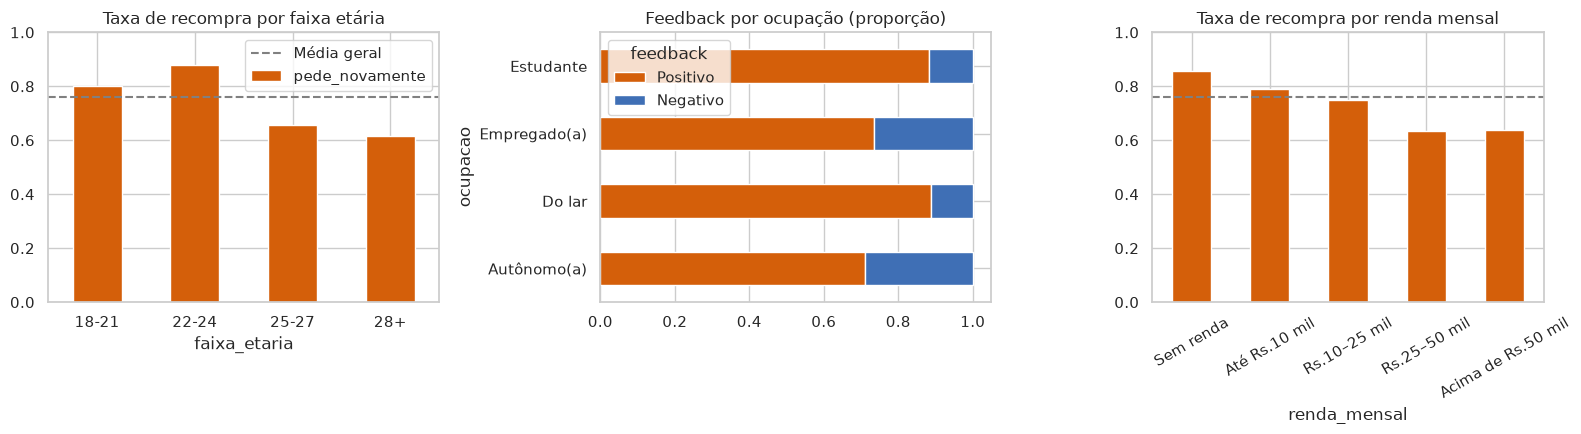

In [10]:
recompra_por_faixa = df.groupby("faixa_etaria")["pede_novamente"].apply(lambda s: (s == "Sim").mean())
feedback_por_ocupacao = pd.crosstab(df["ocupacao"], df["feedback"], normalize="index")
ordem_renda = list(TRADUCOES["renda_mensal"].values())
recompra_por_renda = df.groupby("renda_mensal")["pede_novamente"].apply(lambda s: (s == "Sim").mean()).reindex(ordem_renda)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
recompra_por_faixa.plot(kind="bar", color=COR_SIM, ax=axes[0], rot=0)
axes[0].axhline(taxa_recompra, color="gray", linestyle="--", label="Média geral")
axes[0].set_title("Taxa de recompra por faixa etária")
axes[0].set_ylim(0, 1)
axes[0].legend()

feedback_por_ocupacao[["Positivo", "Negativo"]].plot(kind="barh", stacked=True, color=[COR_SIM, COR_NAO], ax=axes[1])
axes[1].set_title("Feedback por ocupação (proporção)")

recompra_por_renda.plot(kind="bar", color=COR_SIM, ax=axes[2], rot=30)
axes[2].axhline(taxa_recompra, color="gray", linestyle="--")
axes[2].set_title("Taxa de recompra por renda mensal")
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Leitura rápida:** a taxa de recompra cai a partir dos 25 anos (mesmo achado da EDA, Qui² p≈0,0001), e a satisfação muda com a ocupação (Qui² p≈0,011). Esses dois cortes viram os visuais principais do Dashboard 2.

## 6. Teste da correlação do Dashboard 1

In [11]:
VARS_CORRELACAO = ["idade", "tamanho_familia", "renda_nivel", "escolaridade_nivel", "latitude", "longitude"]
df[VARS_CORRELACAO].corr(method="spearman").round(2)

,idade,tamanho_familia,renda_nivel,escolaridade_nivel,latitude,longitude
idade,1.00,0.17,0.57,-0.00,0.06,0.05
tamanho_familia,0.17,1.00,0.07,-0.04,-0.03,0.07
renda_nivel,0.57,0.07,1.00,0.02,-0.04,0.10
escolaridade_nivel,-0.00,-0.04,0.02,1.00,-0.04,-0.11
latitude,0.06,-0.03,-0.04,-0.04,1.00,-0.19
longitude,0.05,0.07,0.10,-0.11,-0.19,1.00


## 7. Exportação

- **Original:** `data/raw/online_food_delivery.csv` (salvo no passo 1, fora do Git).
- **Tratado:** `data/clean/dataset.csv` (versionado, porque o Streamlit Community Cloud só enxerga o que está no GitHub).

In [12]:
CAMINHO_CLEAN.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CAMINHO_CLEAN, index=False)
print("Exportado:", CAMINHO_CLEAN.relative_to(RAIZ), df.shape)

Exportado: data/clean/dataset.csv (285, 15)
